<div style="background-color:#f5f5f5; padding:20px; border-radius:10px; border:1px solid #e0e0e0;">
<table style="width:100%; border:none;"><tr style="border:none;">
<td style="width:20%;text-align:center;border:none;vertical-align:middle;">
<img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="University of Isfahan" width="90">
</td>
<td style="width:60%;text-align:center;border:none;vertical-align:middle;">
<h1 style="margin:0;color:#333;">University of Isfahan</h1>
<h2 style="margin:0;color:#555;font-weight:normal;">Faculty of Mathematics and Statistics</h2>
<hr style="border:1px solid #ccc;margin-top:15px;margin-bottom:15px;">
<h3 style="margin:0;color:#0056b3;">Practical Homework: Gradient Descent</h3>
</td>
<td style="width:20%;text-align:center;border:none;vertical-align:middle;">
<img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="University of Isfahan" width="90">
</td></tr></table></div>


<div style="font-size:1.1em;margin-top:20px;margin-bottom:20px;">
<table style="width:70%;margin-left:auto;margin-right:auto;border:none;">
<tr><td style="text-align:right;padding:6px;"><strong>Course:</strong></td><td style="padding:6px;">Machine Learning</td></tr>
<tr><td style="text-align:right;padding:6px;"><strong>Instructor:</strong></td><td style="padding:6px;">Dr. Fatemeh Mansoori</td></tr>
<tr><td style="text-align:right;padding:6px;"><strong>Semester:</strong></td><td style="padding:6px;">Fall 2026</td></tr>
<tr><td style="text-align:right;padding:6px;"><strong>Student Name:</strong></td><td style="padding:6px;"><em>Your Name Here</em></td></tr>
<tr><td style="text-align:right;padding:6px;"><strong>Student ID:</strong></td><td style="padding:6px;"><em>Your Student ID Here</em></td></tr>
</table></div>


## **Gradient Descent: From a Regression Line to the Cost Surface**

In this homework, we will use **batch gradient descent** to solve a linear regression problem and investigate what happens to the model and its cost during training.

We will work with a small synthetic dataset relating the **size of a video file (GB)** to the **time needed to process it (minutes)**. The goal is not just to find a fitted line, but also to *see how gradient descent moves toward that line*.

We will follow the same approach as in the lecture notebook: prepare `X_b`, calculate the cost, update the parameters, store the history, and visualize the results. The final experiment compares **small, suitable, and overly large learning rates**.

**Instructions:** Complete the code cells with `TODO` and answer the questions marked **Your Task**. The data and most plotting code have already been provided. Use NumPy and Matplotlib only; do not use a ready-made regression or optimizer function.


### **1. Setup: Importing Libraries and Preparing the Data**

Our model has one input variable, $x$, and one target, $y$. We will add a column of ones to the input array so that the intercept can be handled as another model parameter.

The dataset is generated with a fixed random seed, so everyone works with the **same observations**. Run the following cell and examine the scatter plot.


X shape: (50,)
X_b shape: (50, 2)
y shape: (50,)


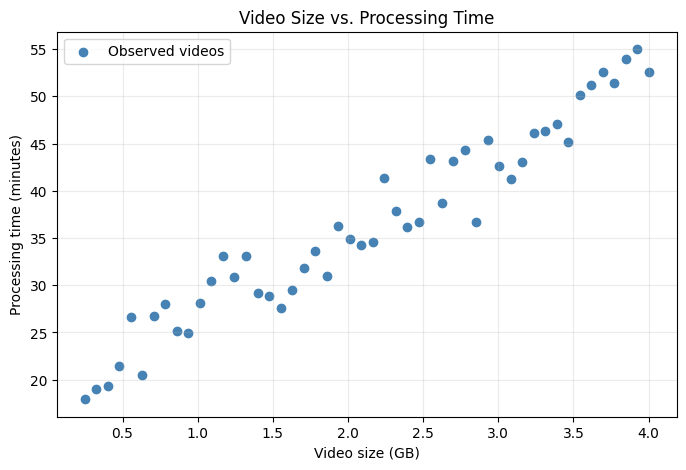

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- The Dataset ---
rng = np.random.default_rng(22)
X = np.linspace(0.25, 4.0, 50)  # Video size in GB
y = 19 + 8 * X + rng.normal(0, 2.2, len(X))  # Processing time in minutes
m = len(y)

# Add a column of ones for the intercept (theta_0)
X_b = np.c_[np.ones((m, 1)), X]

print('X shape:', X.shape)
print('X_b shape:', X_b.shape)
print('y shape:', y.shape)

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='steelblue', label='Observed videos')
plt.title('Video Size vs. Processing Time')
plt.xlabel('Video size (GB)')
plt.ylabel('Processing time (minutes)')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### **2. Defining the Hypothesis and the Cost Function**

We want to learn the weights $w_0$ and $w_1$ of a line:

$$
h_w(x)=w_0+w_1x.
$$

In the Python cells, we use the name `theta = [w_0, w_1]`, as in the lecture notebook. With the design matrix `X_b`, all the predictions can be calculated at once:

$$
\widehat{\mathbf{y}}=X_b\boldsymbol{\theta}.
$$

We will use the average sum of squared errors (SSE divided by the training size):

$$
J(\mathbf{w})=\frac{SSE}{m}=\frac{1}{m}\sum_{i=1}^{m}\left(h_w(x^{(i)})-y^{(i)}\right)^2.
$$

A smaller cost means the predictions are closer to the observations. The function below computes this cost.

**Note:** Dividing by $m$ rescales the error; it does not by itself prevent overflow when weights diverge. That is why the learning-rate experiment later is important.


In [2]:
def compute_cost(X_b, y, theta):
    """Average squared error: J(theta) = SSE / m."""
    m = len(y)
    predictions = X_b @ theta
    errors = predictions - y
    return np.sum(errors ** 2) / m

initial_theta = np.zeros(2)
print('Cost before training:', compute_cost(X_b, y, initial_theta))

Cost before training: 1422.9734116761026


### **2A. Your Task: Linear Regression Using the Analytical Formula**

Before using gradient descent, find the regression line **directly**, as in the earlier *Linear Regression: Analytical Solution* exercise. For a design matrix $X_b$ with a column of ones, the **Normal Equation** is

$$
\boldsymbol{\theta}_{\mathrm{closed}}=(X_b^T X_b)^{-1}X_b^T\mathbf{y}.
$$

Here, $\boldsymbol{\theta}_{\mathrm{closed}}=[w_0,w_1]^T$. For this dataset, $X_b^T X_b$ is invertible.

**Your Task:** Complete `linear_regression_closed_form` using NumPy matrix multiplication and `np.linalg.inv`, following the analytical approach in the reference notebook. Print the coefficients and the cost of your solution. Do not use `sklearn.linear_model`, `np.polyfit`, or a gradient descent function for this part.


In [ ]:
def linear_regression_closed_form(X_b, y):
    """Find [w0, w1] using the Normal Equation."""
    # TODO: Apply theta = (X_b.T @ X_b)^(-1) @ X_b.T @ y.
    raise NotImplementedError('Implement the Normal Equation')


theta_closed = linear_regression_closed_form(X_b, y)
print('Closed-form weights (w0, w1):', np.round(theta_closed, 4))
print('Closed-form cost:', round(compute_cost(X_b, y, theta_closed), 4))

In [ ]:
# Visualize the fitted line obtained analytically.
plt.figure(figsize=(9, 5))
plt.scatter(X, y, color='steelblue', label='Actual data')
plt.plot(X, X_b @ theta_closed, color='darkorange', linewidth=2.5,
         label='Regression line (Normal Equation)')
plt.xlabel('Video size (GB)')
plt.ylabel('Processing time (minutes)')
plt.title('Linear Regression — Analytical Solution')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### **3. Your Task: Implement the Gradient Descent Algorithm**

Gradient descent gradually improves the weights by moving in the **opposite direction of the gradient**. With learning rate $\eta$, the update rule is:

$$
w_0 \leftarrow w_0-\eta\frac{\partial J}{\partial w_0}
=w_0-\eta\frac{2}{m}\sum_{i=1}^{m}\left(h_w(x^{(i)})-y^{(i)}\right)
$$

$$
w_1 \leftarrow w_1-\eta\frac{\partial J}{\partial w_1}
=w_1-\eta\frac{2}{m}\sum_{i=1}^{m}\left(h_w(x^{(i)})-y^{(i)}\right)x^{(i)}.
$$

These two updates can be calculated together using the design matrix:

$$
\boldsymbol{\theta}\leftarrow\boldsymbol{\theta}-\eta\frac{2}{m}X_b^{T}(X_b\boldsymbol{\theta}-\mathbf{y}).
$$

**Important mathematical detail:** The factor $2/m$ is necessary because our cost is $SSE/m$. If the cost were $SSE/(2m)$, the factor would instead be $1/m$—which is the convention used in our earlier lecture notebook. The minimizer is the same, but the gradient sizes differ.

**Your Task:** Complete the four missing operations inside the loop: (1) predictions, (2) errors, (3) gradients, and (4) parameter update. Keep track of the cost **after** each update and a copy of the weights at **every** step, including the initial weights.


In [ ]:
def gradient_descent(X_b, y, theta, alpha, iterations):
    """Return final theta, cost history, and weight history."""
    m = len(y)
    theta = np.asarray(theta, dtype=float).copy()
    cost_history = np.zeros(iterations)
    theta_history = [theta.copy()]

    for i in range(iterations):
        # --- YOUR TASK ---
        # 1. Compute predictions using X_b and theta.
        # 2. Compute the prediction errors.
        # 3. Compute the vectorized gradient for J = SSE / m.
        # 4. Update theta using alpha and the gradient.
        raise NotImplementedError('Replace this line with your four gradient descent steps')
        # -----------------

        cost_history[i] = compute_cost(X_b, y, theta)
        theta_history.append(theta.copy())

    return theta, cost_history, theta_history

### **4. Running Gradient Descent and Observing the Regression Line**

Let's first train the model with a single learning rate. We start with the neutral hypothesis $h_w(x)=0$, which corresponds to `theta = [0, 0]`.

The arrays `theta_history` and `cost_history` will let us examine **how the line and the error change** through training.


In [ ]:
alpha = 0.08
iterations = 350
initial_theta = np.zeros(2)

theta_final, cost_history, theta_history = gradient_descent(
    X_b, y, initial_theta, alpha, iterations
)

print('Initial theta:', initial_theta)
print('Final theta:', np.round(theta_final, 4))
print('Initial cost:', round(compute_cost(X_b, y, initial_theta), 4))
print('Final cost:', round(cost_history[-1], 4))
print('Weights recorded:', len(theta_history))

#### **Visualizing Gradient Descent Progression**

Each set of weights in `theta_history` defines a different line. Instead of showing all 351 lines, we draw **every 25th line** in light red and the final fitted line in dark red.


In [ ]:
plt.figure(figsize=(9, 5))
plt.scatter(X, y, color='steelblue', label='Actual data')

for theta_step in theta_history[::25]:
    plt.plot(X, X_b @ theta_step, color='tomato', alpha=0.20)

plt.plot(X, X_b @ theta_final, color='firebrick', linewidth=2.5, label='Final fitted line')
plt.title('Gradient Descent Progression')
plt.xlabel('Video size (GB)')
plt.ylabel('Processing time (minutes)')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

#### **Cost over Iterations**

If gradient descent is approaching a good solution, the cost should decrease and eventually stabilize. We can investigate this by plotting the cost after every update.


In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, iterations + 1), cost_history, color='purple', linewidth=2)
plt.title('Cost during Gradient Descent')
plt.xlabel('Iteration')
plt.ylabel('J(theta) = SSE / m')
plt.grid(alpha=0.25)
plt.show()

**Your Task — Understanding the Results:** Answer briefly, using the two plots above.

1. What are the intercept $w_0$ and slope $w_1$ of your final model? What does each mean in this application?
2. Why is the first regression line horizontal at $y=0$?
3. Does the cost reach exactly zero? Explain your observation.

**Your answer:**

*Write your answer here.*


### **5. Your Task: Plotting the Cost Function Surface**

The previous plots show **what** gradient descent does. But **why** does it find a low-cost solution?

Since a univariate linear model has two weights, the cost $J(w_0,w_1)$ can be visualized as a surface in three dimensions. Every point on this surface corresponds to a different pair of weights and has a height equal to the cost.

First, create a grid of possible values of $w_0$ and $w_1$. **Your Task:** In the nested loop, evaluate `compute_cost` at each weight pair and save the result in `J_vals[i, j]`.


In [ ]:
w0_vals = np.linspace(0, 40, 85)
w1_vals = np.linspace(-4, 20, 85)
W0, W1 = np.meshgrid(w0_vals, w1_vals)
J_vals = np.zeros_like(W0)

for i in range(len(w1_vals)):
    for j in range(len(w0_vals)):
        trial_theta = np.array([W0[i, j], W1[i, j]])
        # TODO: Calculate the cost for trial_theta and put it in J_vals[i, j].
        raise NotImplementedError('Calculate the cost for each parameter pair')

#### **The Cost Surface and Its Logarithm**

The first plot shows $J(w_0,w_1)$ directly. For the second plot, we display $\log J(w_0,w_1)$ so that cost values of very different magnitudes are easier to compare.

The logarithm changes **only the display**; our algorithm still minimizes $J$, not $\log J$. We use `np.maximum` to avoid taking the logarithm of zero.


In [ ]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(W0, W1, J_vals, cmap='viridis', alpha=0.92)
ax.set_title('Cost Function Surface')
ax.set_xlabel('w0 (intercept)')
ax.set_ylabel('w1 (slope)')
ax.set_zlabel('J(w) = SSE / m')
plt.show()

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(W0, W1, np.log(np.maximum(J_vals, 1e-12)), cmap='viridis')
ax.set_title('Log-Cost Surface')
ax.set_xlabel('w0 (intercept)')
ax.set_ylabel('w1 (slope)')
ax.set_zlabel('log(J(w))')
plt.show()

### **6. Visualizing the Path of Gradient Descent**

We now want to check whether the sequence of learned weights actually moves toward the low region of the cost surface.

Because `theta_history` includes the **initial weights** and each updated pair, it has 351 entries. `cost_history` contains only the 350 costs **after** updating. To plot the path correctly, we calculate the cost again for every recorded pair of weights.


In [ ]:
theta_path = np.asarray(theta_history)
path_cost = np.array([compute_cost(X_b, y, t) for t in theta_path])

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(W0, W1, np.log(np.maximum(J_vals, 1e-12)),
                cmap='viridis', alpha=0.28)

# The gradient descent path (including the initial point)
ax.plot(theta_path[:, 0], theta_path[:, 1],
        np.log(np.maximum(path_cost, 1e-12)),
        color='crimson', linewidth=2.0, label='Gradient descent path')
ax.scatter(theta_path[0, 0], theta_path[0, 1],
           np.log(max(path_cost[0], 1e-12)), color='black', s=40, label='Start')
ax.scatter(theta_path[-1, 0], theta_path[-1, 1],
           np.log(max(path_cost[-1], 1e-12)), color='limegreen', s=50, label='End')

ax.set_title('Gradient Descent Path on the Log-Cost Surface')
ax.set_xlabel('w0 (intercept)')
ax.set_ylabel('w1 (slope)')
ax.set_zlabel('log(J(w))')
ax.legend(loc='upper right')
plt.show()

**Your Task — Interpreting the Surface:**

1. Where is the lowest-cost region on the surface, relative to the weights printed in Section 4?
2. What happens to the step sizes as the red path approaches the minimum?
3. Does plotting $\log J$ mean that the algorithm is updating the weights using the gradient of $\log J$? Explain.

**Your answer:**

*Write your answer here.*


### **6A. Your Task: How Do Different Initial Weights Affect Gradient Descent?**

In the previous sections, gradient descent started with $w_0=0$ and $w_1=0$. As in the visualization exercises from previous terms, let us change the **starting weights**, hold the **learning rate constant**, and observe how the regression lines and optimization paths change.

Run gradient descent for **120 iterations** at $\eta=0.08$ using these three starting points:

$$
\boldsymbol{\theta}^{(0)}\in\left\{[0,0]^T,\ [35,-3]^T,\ [5,15]^T\right\}.
$$

**Your Task:** Use your *existing* `gradient_descent` function for each initial weight pair. Complete the loop below and store each run's final weights, cost history, and weight history. All runs must use the **same dataset, learning rate, and number of iterations**. Do not modify the gradient descent function.

Then examine the provided plots. Try replacing one starting pair with another pair of your choice (for example, inside the $w_0$ and $w_1$ ranges used for the cost surface) and describe what changes.


In [ ]:
initial_weight_choices = [
    np.array([0.0, 0.0]),
    np.array([35.0, -3.0]),
    np.array([5.0, 15.0]),
]
weight_alpha = 0.08
weight_iterations = 120
weight_runs = []

for starting_theta in initial_weight_choices:
    # TODO: Call gradient_descent with starting_theta, weight_alpha,
    #       and weight_iterations.
    # TODO: Append a dictionary with keys 'start', 'final', 'cost', 'path'
    #       to weight_runs; use copies for the weight arrays where needed.
    raise NotImplementedError('Train from each initial weight pair and save its history')

for run in weight_runs:
    print(f"start={run['start']}, final={np.round(run['final'], 3)}, "
          f"final cost={run['cost'][-1]:.4f}")

#### **Plotting the Lines for Different Initial Weights**

Each panel shows the starting line (dashed), several intermediate lines (faint), and the final line after **120 updates**. The black dotted line is the analytical solution from Section 2A, which gives us a reference for comparison.


In [ ]:
fig, axes = plt.subplots(1, len(weight_runs), figsize=(15, 4.7), sharex=True, sharey=True)
axes = np.atleast_1d(axes)

for ax, run in zip(axes, weight_runs):
    ax.scatter(X, y, color='steelblue', s=18, label='Data')
    path = np.asarray(run['path'])
    ax.plot(X, X_b @ path[0], color='gray', linestyle='--', linewidth=1.8,
            label='Initial line')
    for step in [1, 5, 15, 40, 80]:
        if step < len(path):
            ax.plot(X, X_b @ path[step], color='tomato', alpha=0.30)
    ax.plot(X, X_b @ run['final'], color='firebrick', linewidth=2.3,
            label='Final GD line')
    ax.plot(X, X_b @ theta_closed, color='black', linestyle=':', linewidth=2,
            label='Closed-form line')
    ax.set_title(f"Starting weights: {run['start']}")
    ax.set_xlabel('Video size (GB)')
    ax.grid(alpha=0.2)

axes[0].set_ylabel('Processing time (minutes)')
axes[-1].legend(fontsize=8, loc='best')
plt.suptitle('Evolution of Regression Lines from Different Initial Weights')
plt.tight_layout()
plt.show()

#### **Cost Curves and Optimization Paths**

The reference notebook visualizes gradient descent on the **logarithmic cost surface** and compares convergence curves. Here, repeat that idea while keeping $\eta$ fixed and changing only the **initial weights**.

The first plot compares the costs after each update. The second places each run's weight trajectory on the *same* log-cost surface from Section 5. The star marks the weights obtained by the Normal Equation.


In [ ]:
colors = ['royalblue', 'darkorange', 'forestgreen', 'purple', 'crimson']

plt.figure(figsize=(9, 5))
for index, run in enumerate(weight_runs):
    label = f"start={run['start']}"
    plt.semilogy(range(1, weight_iterations + 1), run['cost'],
                 label=label, color=colors[index % len(colors)], linewidth=2)
plt.xlabel('Iteration')
plt.ylabel('J(w) = SSE / m (logarithmic scale)')
plt.title('Effect of Initial Weights on Convergence (Fixed Learning Rate)')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(W0, W1, np.log(np.maximum(J_vals, 1e-12)),
                cmap='viridis', alpha=0.22)

for index, run in enumerate(weight_runs):
    path = np.asarray(run['path'])
    path_cost = np.array([compute_cost(X_b, y, t) for t in path])
    color = colors[index % len(colors)]
    ax.plot(path[:, 0], path[:, 1], np.log(np.maximum(path_cost, 1e-12)),
            color=color, linewidth=2, label=f"start={run['start']}")
    ax.scatter(path[0, 0], path[0, 1], np.log(max(path_cost[0], 1e-12)),
               color=color, s=36)

ax.scatter(theta_closed[0], theta_closed[1],
           np.log(max(compute_cost(X_b, y, theta_closed), 1e-12)),
           color='black', marker='*', s=100, label='Normal Equation minimum')
ax.set_xlabel('w0 (intercept)')
ax.set_ylabel('w1 (slope)')
ax.set_zlabel('log(J(w))')
ax.set_title('Different Starting Weights on the Log-Cost Surface')
ax.legend(loc='upper right', fontsize=8)
plt.show()

**Your Task — Interpreting the Effect of Initial Weights:**

1. How do the *initial* regression lines differ in the three panels? Which one seems closest to the data before training?
2. Compare the cost curves. Does a lower **initial** cost guarantee faster convergence?
3. After **120 iterations**, are the final weights identical? Compare them with $\boldsymbol{\theta}_{\mathrm{closed}}$ from the Normal Equation. Explain the differences.
4. In the 3D log-cost plot, do the paths start in the same place? What happens as training proceeds?
5. Choose one **new** pair of initial weights, rerun the experiment, and describe how the fitted line and the cost curve change. Keep $\eta$ and the iteration count unchanged.

**Your answer:**

*Write your answer here.*


### **7. Your Task: The Effect of the Learning Rate ($\eta$)**

Choosing $\eta$ is crucial:

- A **very small** learning rate makes the algorithm move slowly.
- A **suitable** learning rate gives steady improvement.
- A **very large** learning rate can cause the model to **diverge**, so the cost grows rather than shrinks.

In the next experiment, run **120 iterations** starting from `theta = [0, 0]` for each rate:

$$
\eta \in \{0.0005,\ 0.08,\ 0.20\}.
$$

**Your Task:** Call your `gradient_descent` function once for each rate. Store the final weights and two histories in the dictionary `experiments`. Be sure every run starts with the **same initial weights**.


In [ ]:
learning_rates = [0.0005, 0.08, 0.20]
experiment_iterations = 120
experiments = {}

for eta in learning_rates:
    # TODO: run gradient_descent with np.zeros(2) and experiment_iterations.
    # TODO: store {'theta': ..., 'cost': ..., 'path': ...} in experiments[eta].
    raise NotImplementedError('Run GD for this learning rate and record the results')

for eta in learning_rates:
    print(f'eta={eta}: final cost={experiments[eta]["cost"][-1]:.4g}, '
          f'theta={experiments[eta]["theta"]}')

#### **Comparing Convergence and Divergence**

In the same spirit as the reference homework, we separate the two stable runs from the diverging run: a very large cost can flatten other curves so much that their differences become invisible.

We then use a **logarithmic vertical axis** to inspect all three curves together.


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(experiments[0.0005]['cost'], label='eta = 0.0005 (small)', color='royalblue')
ax1.plot(experiments[0.08]['cost'], label='eta = 0.08 (suitable)', color='forestgreen')
ax1.set_title('Two Converging Runs')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('J(w) = SSE / m')
ax1.legend()
ax1.grid(alpha=0.25)

ax2.plot(experiments[0.20]['cost'], label='eta = 0.20 (too large)', color='crimson')
ax2.set_title('Divergence (Linear Scale)')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('J(w) = SSE / m')
ax2.legend()
ax2.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
for eta, color in zip(learning_rates, ['royalblue', 'forestgreen', 'crimson']):
    plt.semilogy(experiments[eta]['cost'], label=f'eta = {eta}', color=color, linewidth=2)
plt.title('Learning Rate Comparison (Logarithmic Cost Axis)')
plt.xlabel('Iteration')
plt.ylabel('J(w) (logarithmic y-axis)')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

#### **Extra: How Do the Regression Lines Change?**

Finally, compare a few intermediate regression lines for the **small and suitable rates**. For the diverging rate, the predictions may become far too large to draw on the same axes as the observations. This is expected, not a plotting bug.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, eta, color in zip(axes, [0.0005, 0.08], ['royalblue', 'forestgreen']):
    ax.scatter(X, y, color='gray', s=20, label='Data')
    for t in experiments[eta]['path'][::12]:
        ax.plot(X, X_b @ t, color=color, alpha=0.18)
    ax.plot(X, X_b @ experiments[eta]['theta'], color=color, lw=2.5,
            label='Final line after 120 steps')
    ax.set_title(f'eta = {eta}')
    ax.set_xlabel('Video size (GB)')
    ax.legend()
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Processing time (minutes)')
plt.tight_layout()
plt.show()

### **8. Your Task: Analysis of Different Choices for the Learning Rate**

Examine the figures and your printed results carefully. Answer the following questions with **your own observations**:

1. **Small rate ($\eta=0.0005$):** How does its cost curve compare with the suitable learning rate? Why is the fitted line still far from its final position after 120 steps?
2. **Suitable rate ($\eta=0.08$):** Describe its cost curve. Does it make substantial progress within 120 updates?
3. **Large rate ($\eta=0.20$):** How do the weights and cost change? Explain why a large learning rate can repeatedly overshoot the minimum.
4. **Logarithmic plot:** Why might the diverging cost appear almost flat at first on a normal linear plot? What is easier to see on the logarithmic plot?
5. **Connecting to the formula:** If we changed the cost from $SSE/m$ to $SSE/(2m)$ but left the learning rate unchanged, what would happen to the size of each gradient descent update?

**Your answer:**

*Write your response here.*


### **Optional Challenge: Multivariable Linear Regression**

The lecture notebook also shows that the **same vectorized gradient descent function** works with more than one feature. Suppose processing time depends on both **video size** and a **complexity index**:

$$
h_w(x_1,x_2)=w_0+w_1x_1+w_2x_2.
$$

Run the provided data cell, then reuse your function from Section 3. There should now be **three parameters**, so `theta` must start with three zeros. No new gradient formula or optimizer is required.

**Your Task (optional):** Create the new design matrix, train for 350 iterations with `alpha = 0.08`, print the weights, and plot the cost curve. Explain in one sentence what $w_2$ means.


In [ ]:
rng_multi = np.random.default_rng(30)
size_multi = np.linspace(0.25, 4.0, 50)
complexity_multi = rng_multi.uniform(0, 1, len(size_multi))
y_multi = 12 + 7 * size_multi + 10 * complexity_multi + rng_multi.normal(0, 1.5, len(size_multi))

X_multi = np.column_stack((size_multi, complexity_multi))
print('Input feature matrix shape:', X_multi.shape)

In [ ]:
# OPTIONAL: Reuse the SAME gradient_descent function with two features.
# TODO: add a column of ones to X_multi.
# TODO: initialize three weights and train for 350 iterations (alpha = 0.08).
# TODO: print the final weights and plot the cost against iteration.

---

**Before submitting:** Complete the `TODO` cells, write your answers below the relevant sections, and use **Kernel → Restart & Run All** to verify that the notebook runs from beginning to end. Keep all plots and printed outputs in the submitted notebook.
